In [1]:
from pathlib import Path
import sys


ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "services"))

# print(Path.cwd(), ROOT)

In [2]:
from services.allocator import Allocator

svc = Allocator()

In [3]:
svc.ingester_prepper.load_option_chain("SPY")
df = svc.ingester_prepper.process_SPY_option_chain__for_income()
df


SPY shape: (3_587_783, 13)
┌─────────────┬────────────┬─────────────┬────────────┬───┬────────────┬────────┬───────┬──────────┐
│ QUOTE_READT ┆ QUOTE_DATE ┆ UNDERLYING_ ┆ EXPIRE_DAT ┆ … ┆ STRIKE_DIS ┆ P_BID  ┆ P_ASK ┆ P_DELTA  │
│ IME         ┆ ---        ┆ LAST        ┆ E          ┆   ┆ TANCE      ┆ ---    ┆ ---   ┆ ---      │
│ ---         ┆ date       ┆ ---         ┆ ---        ┆   ┆ ---        ┆ f64    ┆ f64   ┆ f64      │
│ datetime[μs ┆            ┆ f64         ┆ date       ┆   ┆ str        ┆        ┆       ┆          │
│ ]           ┆            ┆             ┆            ┆   ┆            ┆        ┆       ┆          │
╞═════════════╪════════════╪═════════════╪════════════╪═══╪════════════╪════════╪═══════╪══════════╡
│ 2021-09-01  ┆ 2021-09-01 ┆ 451.85      ┆ 2021-09-01 ┆ … ┆ 181.900000 ┆ 0.0    ┆ 0.01  ┆ -0.00024 │
│ 16:00:00    ┆            ┆             ┆            ┆   ┆            ┆        ┆       ┆          │
│ 2021-09-01  ┆ 2021-09-01 ┆ 451.85      ┆ 2021-09-01 ┆ … ┆ 176

QUOTE_READTIME,QUOTE_DATE,UNDERLYING_LAST,EXPIRE_DATE,DTE,C_BID,C_ASK,C_DELTA,STRIKE,STRIKE_DISTANCE,P_BID,P_ASK,P_DELTA
datetime[μs],date,f64,date,i64,f64,f64,f64,f64,str,f64,f64,f64
2021-09-01 16:00:00,2021-09-01,451.85,2021-09-01,0,181.09,182.31,1.0,270.0,""" 181.900000""",0.0,0.01,-0.00024
2021-09-01 16:00:00,2021-09-01,451.85,2021-09-01,0,176.09,177.31,1.0,275.0,""" 176.900000""",0.0,0.01,-0.00063
2021-09-01 16:00:00,2021-09-01,451.85,2021-09-01,0,171.09,172.31,1.0,280.0,""" 171.900000""",0.0,0.01,0.0
2021-09-01 16:00:00,2021-09-01,451.85,2021-09-01,0,166.14,167.3,1.0,285.0,""" 166.900000""",0.0,0.01,-0.00016
2021-09-01 16:00:00,2021-09-01,451.85,2021-09-01,0,161.09,162.31,1.0,290.0,""" 161.900000""",0.0,0.01,-0.00068
…,…,…,…,…,…,…,…,…,…,…,…,…
2021-02-26 16:00:00,2021-02-26,380.36,2023-12-15,1022,4.0,7.0,0.10857,570.0,""" 189.600000""",196.2,200.5,-0.9743
2021-02-26 16:00:00,2021-02-26,380.36,2023-12-15,1022,4.22,5.8,0.10086,575.0,""" 194.600000""",200.92,205.5,-0.97337
2021-02-26 16:00:00,2021-02-26,380.36,2023-12-15,1022,4.0,6.01,0.10031,580.0,""" 199.600000""",205.0,210.0,-0.97362


In [4]:
# eds = df["EXPIRE_DATE"].unique()
# eds

In [5]:
import datetime
import polars as pl

(
    df.filter(
        (pl.col("QUOTE_DATE") > datetime.date(2020, 1, 1))
        & (pl.col("EXPIRE_DATE") == datetime.date(2020, 1, 3))
        & (pl.col("STRIKE") > 320.)
        & (pl.col("STRIKE") < 330.)
    )
)


QUOTE_READTIME,QUOTE_DATE,UNDERLYING_LAST,EXPIRE_DATE,DTE,C_BID,C_ASK,C_DELTA,STRIKE,STRIKE_DISTANCE,P_BID,P_ASK,P_DELTA
datetime[μs],date,f64,date,i64,f64,f64,f64,f64,str,f64,f64,f64
2020-01-02 16:00:00,2020-01-02,324.87,2020-01-03,1,4.07,4.16,1.0,320.5,""" 4.400000""",0.03,0.04,-0.03561
2020-01-02 16:00:00,2020-01-02,324.87,2020-01-03,1,3.74,3.86,1.0,321.0,""" 3.900000""",0.04,0.06,-0.04668
2020-01-02 16:00:00,2020-01-02,324.87,2020-01-03,1,3.19,3.26,1.0,321.5,""" 3.400000""",0.05,0.06,-0.05911
2020-01-02 16:00:00,2020-01-02,324.87,2020-01-03,1,2.62,2.71,1.0,322.0,""" 2.900000""",0.09,0.09,-0.08728
2020-01-02 16:00:00,2020-01-02,324.87,2020-01-03,1,2.22,2.25,1.0,322.5,""" 2.400000""",0.11,0.11,-0.11665
…,…,…,…,…,…,…,…,…,…,…,…,…
2020-01-03 16:00:00,2020-01-03,322.43,2020-01-03,0,0.03,0.01,0.02166,327.5,""" 5.100000""",4.64,4.84,-1.0
2020-01-03 16:00:00,2020-01-03,322.43,2020-01-03,0,0.0,0.01,0.00669,328.0,""" 5.600000""",5.17,5.25,-1.0
2020-01-03 16:00:00,2020-01-03,322.43,2020-01-03,0,0.01,0.0,0.01102,328.5,""" 6.100000""",5.7,5.88,-1.0


In [8]:
df.select(
    pl.col("QUOTE_DATE"),
    pl.col("EXPIRE_DATE"),
    pl.col("STRIKE"),
    pl.col("C_ASK"),
    pl.col("P_ASK"),
).group_by(
    pl.col("QUOTE_DATE"),
    pl.col("EXPIRE_DATE"),
).agg(
    pl.col("STRIKE").max().name.prefix("MAX_"),
    pl.col("STRIKE").min().name.prefix("MIN_"),
    pl.col("C_ASK").max().name.prefix("MAX_"),
    pl.col("P_ASK").max().name.prefix("MAX_"),
).with_columns(
    (pl.col("MAX_STRIKE") - pl.col("MIN_STRIKE")).alias("STRIKE_DIFF"),
    (pl.col("MAX_C_ASK") + pl.col("MAX_P_ASK")).alias("C_PLUS_P_ASK"),
).with_columns(
    (pl.col("STRIKE_DIFF") - pl.col("C_PLUS_P_ASK")).alias("INTEREST_PMT"),
).with_columns(
    (pl.col("INTEREST_PMT") / pl.col("C_PLUS_P_ASK")).alias("PCT_INTEREST_PMT"),
).sort("PCT_INTEREST_PMT", descending=True)

QUOTE_DATE,EXPIRE_DATE,MAX_STRIKE,MIN_STRIKE,MAX_C_ASK,MAX_P_ASK,STRIKE_DIFF,C_PLUS_P_ASK,INTEREST_PMT,PCT_INTEREST_PMT
date,date,f64,f64,f64,f64,f64,f64,f64,f64
2020-03-09,2020-03-09,371.0,227.0,47.98,95.82,144.0,143.8,0.2,0.001391
2021-02-01,2021-02-12,480.0,185.0,191.44,103.35,295.0,294.79,0.21,0.000712
2021-02-01,2021-02-22,460.0,200.0,176.26,83.56,260.0,259.82,0.18,0.000693
2022-12-21,2022-12-21,455.0,300.0,85.87,69.04,155.0,154.91,0.09,0.000581
2021-02-01,2021-02-10,460.0,205.0,171.44,83.44,255.0,254.88,0.12,0.000471
…,…,…,…,…,…,…,…,…,…
2020-03-24,2020-04-29,250.0,205.0,45.26,19.19,45.0,64.45,-19.45,-0.301784
2020-03-25,2020-04-29,250.0,205.0,48.35,19.69,45.0,68.04,-23.04,-0.338624
2022-06-23,2024-06-21,430.0,335.0,83.5,70.32,95.0,153.82,-58.82,-0.382395


In [20]:
xs = df.filter(
    (pl.col("QUOTE_DATE") == datetime.date(2021, 2, 1)),
    (pl.col("EXPIRE_DATE") == datetime.date(2021, 2, 12)),
)
xs.sort("STRIKE")

QUOTE_READTIME,QUOTE_DATE,UNDERLYING_LAST,EXPIRE_DATE,DTE,C_BID,C_ASK,C_DELTA,STRIKE,STRIKE_DISTANCE,P_BID,P_ASK,P_DELTA
datetime[μs],date,f64,date,i64,f64,f64,f64,f64,str,f64,f64,f64
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,191.26,191.44,0.88449,185.0,""" 191.200000""",0.0,0.01,-0.00016
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,186.27,186.44,0.88722,190.0,""" 186.200000""",0.01,0.02,-0.00024
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,181.27,181.45,0.8904,195.0,""" 181.200000""",0.01,0.02,-0.00019
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,176.27,176.45,0.89244,200.0,""" 176.200000""",0.01,0.02,-0.00098
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,171.25,171.98,0.89418,205.0,""" 171.200000""",0.01,0.02,-0.00053
…,…,…,…,…,…,…,…,…,…,…,…,…
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,0.0,0.01,0.00135,450.0,""" 73.800000""",72.85,73.48,-1.0
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,0.0,0.01,0.00123,455.0,""" 78.800000""",78.09,78.58,-1.0
2021-02-01 16:00:00,2021-02-01,376.19,2021-02-12,11,0.0,0.01,0.00043,460.0,""" 83.800000""",83.14,83.7,-1.0


['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


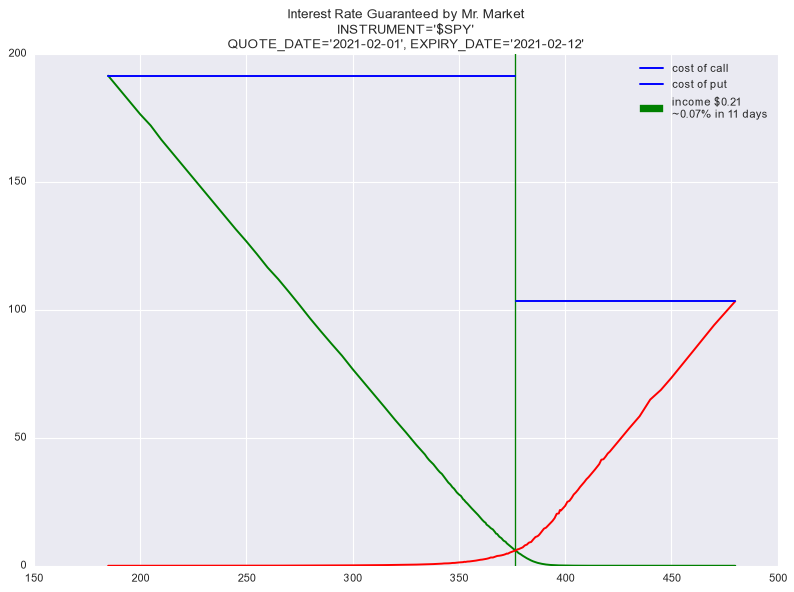

In [44]:
import matplotlib.pyplot as plt
print(plt.style.available)
plt.style.use("seaborn-v0_8")

fig, ax = plt.subplots(figsize=(12, 8))
plt.plot(xs["STRIKE"], xs["C_ASK"], "g-")
plt.plot(xs["STRIKE"], xs["P_ASK"], "r-")

axmin, axmax = 150, 500
# @strike=185, c_ask=191.44
xmin, xmax = (185-axmin)/(axmax - axmin), (185+191.44-axmin)/(axmax - axmin)
plt.axhline(y=191.44, xmin=xmin, xmax=xmax, label="cost of call")

# @strike=480, p_ask=103.35
xmin, xmax = (480-103.35-axmin)/(axmax - axmin), (480-axmin)/(axmax - axmin)
plt.axhline(y=103.35, xmin=xmin, xmax=xmax, label="cost of put")

# interest = strikes spread - (cost of call + put)
xmin, xmax = (185+191.44), (480-103.35)
income = xmax - xmin
total_cost = 191.44+103.35
plt.axvspan(xmin=xmin, xmax=xmax, color="green", label=f"income ${income:.2f}\n~{(income/total_cost)*100:.2f}% in 11 days")

plt.legend()
title = f"Interest Rate Guaranteed by Mr. Market\nINSTRUMENT='$SPY'\nQUOTE_DATE='2021-02-01', EXPIRY_DATE='2021-02-12'"
plt.title(title)

fig.savefig('interest_guarantee.png')